#Importando bibliotecas

In [78]:
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import LabelBinarizer
from sklearn.base import BaseEstimator, ClassifierMixin
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

#Importando dataset

In [28]:
from sklearn.datasets import load_iris

X, y = load_iris(return_X_y=True)

In [29]:
print(X.shape)
print(y.shape)

(150, 4)
(150,)


#Desenvolvimento

In [30]:
#Dividindo em treino e teste
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(x_train.shape)
print(y_train.shape)

(120, 4)
(120,)


##Criando modelo

In [81]:
import numpy as np
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.metrics import accuracy_score

def include_bias(X):
    return np.c_[np.ones(X.shape[0]), X]

def one_hot_encode(y, labels):
    y_hot = np.ones((y.shape[0], len(labels)), dtype=int) * (-1)
    for i, label in enumerate(list(set(y))):
        idxs = np.where(y == label)[0]
        y_hot[idxs, i] = 1
    return y_hot

class MultiLayer(BaseEstimator, ClassifierMixin):
    def __init__(self, hidden_layers=[10], activations=['tanh'], max_iter=10000, learning_rate=0.001):
        self.max_iter = max_iter
        self.learning_rate = learning_rate
        self.hidden_layers = hidden_layers
        self.activations = activations

        if len(self.hidden_layers) != len(self.activations):
            raise ValueError("A lista de ativações deve ter o mesmo tamanho da lista de camadas ocultas.")

    def activate(self, Z, func_name):
        if func_name == 'tanh':
            return np.tanh(Z)
        elif func_name == 'relu':
            return np.maximum(0, Z)
        elif func_name == 'sigmoid':
            return 1 / (1 + np.exp(-Z))
        return Z

    def derivative(self, Z, func_name):
        if func_name == 'tanh':
            return 1 - np.tanh(Z)**2
        elif func_name == 'relu':
            return (Z > 0).astype(float)
        elif func_name == 'sigmoid':
            s = 1 / (1 + np.exp(-Z))
            return s * (1 - s)
        return np.ones_like(Z)

    def forward(self, X):
        self.A = []
        self.Z = []
        AUX = X.copy()

        for i, W in enumerate(self.Ws):
            self.A.append(include_bias(AUX))
            self.Z.append(self.A[-1] @ W)

            act_func = self.activations[i] if i < len(self.activations) else 'linear'
            AUX = self.activate(self.Z[-1], act_func)

        return AUX

    def backward(self, y, y_pred):
        grads = []
        output_delta = y_pred - y
        output_grad = self.A[-1].T @ output_delta
        grads.append(output_grad)

        for i in range(len(self.Ws)-1, 0, -1):
            act_func = self.activations[i-1]
            grad_act = self.derivative(self.Z[i-1], act_func)

            input_delta = (output_delta @ self.Ws[i][1:].T) * grad_act
            grad = self.A[i-1].T @ input_delta
            grads.insert(0, grad)
            output_delta = input_delta.copy()

        for i in range(len(self.Ws)):
            self.Ws[i] -= self.learning_rate * grads[i]

        return self

    def fit(self, X, y):
        self.Ws = []
        previous_output = X.shape[1]

        for n in self.hidden_layers:
            self.Ws.append(np.random.randn(previous_output+1, n))
            previous_output = n

        self.labels = sorted(list(set(y)))
        y_hot = one_hot_encode(y, self.labels)

        self.Ws.append(np.random.randn(previous_output+1, y_hot.shape[1]))

        for _ in range(self.max_iter):
            logits = self.forward(X)
            self.backward(y_hot, logits)

        return self

    def predict(self, X):
        logits = self.forward(X)
        idxs = np.argmax(logits, axis=1)
        return np.array([self.labels[idx] for idx in idxs])

In [82]:
#Criando modelo
model = MultiLayer(hidden_layers=[4, 10, 10, 3], activations=['relu', 'tanh', 'tanh', 'sigmoid'])

In [84]:
#Desempenho no treino
model.fit(x_train, y_train)

y_pred_train = model.predict(x_train)
acc_train = accuracy_score(y_train, y_pred_train)
print(f"Acurácia no Treino: {acc_train * 100:.2f}%")

Acurácia no Treino: 98.33%


In [73]:
#Desempenho no teste
model.fit(x_test, y_test)

y_pred_test = model.predict(x_test)
acc_test = accuracy_score(y_test, y_pred_test)
print(f"Acurácia no Treino: {acc_test * 100:.2f}%")

Acurácia no Treino: 100.00%


##Modelo do Scikit-Learn

In [69]:
lr = 'constant'
lri = 0.1
mlp = MLPClassifier(hidden_layer_sizes=(45), activation='relu', solver='adam', batch_size=32, max_iter=1000, random_state=42, learning_rate=lr, learning_rate_init=lri)
mlp.fit(x_train, y_train)

MLPClassifier(batch_size=32, hidden_layer_sizes=45, learning_rate_init=0.1,
              max_iter=1000, random_state=42)

In [76]:
#Desempenho no treino
acc_treino_sklearn = mlp.score(x_train, y_train)
print(f"Acurácia no treino: {acc_treino_sklearn * 100:.2f}%")

Acurácia no treino: 97.50%


In [77]:
#Desempenho no teste
acc_teste_sklearn = mlp.score(x_test, y_test)
print(f"Acurácia no teste: {acc_teste_sklearn * 100:.2f}%")

Acurácia no teste: 96.67%


#Gráfico comparativo de desempenho

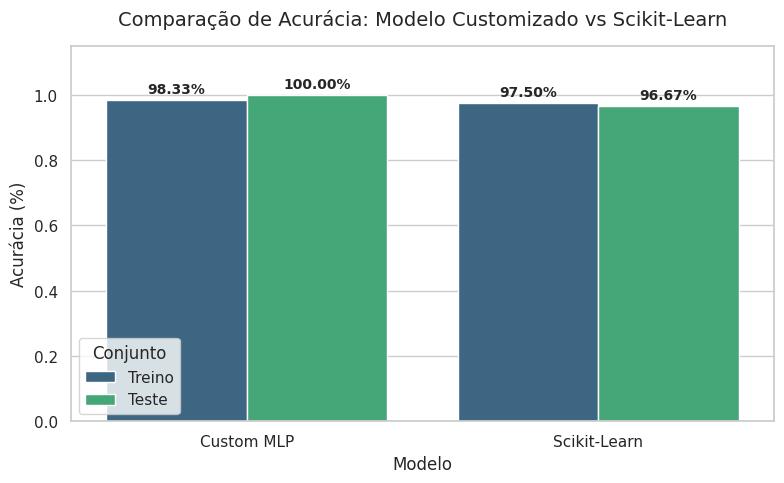

In [80]:
dados = {
    'Modelo': ['Custom MLP', 'Custom MLP', 'Scikit-Learn', 'Scikit-Learn'],
    'Conjunto': ['Treino', 'Teste', 'Treino', 'Teste'],
    'Acurácia': [acc_train, acc_test, acc_treino_sklearn, acc_teste_sklearn]
}

df_comparacao = pd.DataFrame(dados)


plt.figure(figsize=(8, 5))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    x='Modelo',
    y='Acurácia',
    hue='Conjunto',
    data=df_comparacao,
    palette='viridis'
)


plt.title('Comparação de Acurácia: Modelo Customizado vs Scikit-Learn', fontsize=14, pad=15)
plt.xlabel('Modelo', fontsize=12)
plt.ylabel('Acurácia (%)', fontsize=12)
plt.ylim(0, 1.15)

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{height*100:.2f}%',
                    xy=(p.get_x() + p.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()